# Phase 1: Siamese Network for CMU Keystroke Dynamics
**Goal:** Learn per-user typing embeddings from 31 timing features (H, DD, UD).  
**Output:** Trained model + user profile store → feeds Phase 2 (password shortlisting).  
**Dataset:** [CMU Keystroke Dynamics Benchmark](https://www.cs.cmu.edu/~keystroke/) — 51 subjects, 400 samples each.

### Architecture: Siamese Network with Triplet Loss
- Encoder maps 31-dim timing vector → 64-dim L2-normalized embedding
- Triplet loss pushes same-user embeddings together, different-user embeddings apart
- Evaluation metric: **EER (Equal Error Rate)** — standard in keystroke auth literature

In [2]:
# ── Cell 1: Check dataset path ────────────────────────────────────────────────
import os

for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/carnegiecylab/keystroke-dynamics-benchmark-data-set/DSL-StrongPasswordData.csv


In [3]:
# ── Cell 2: Imports & Config ──────────────────────────────────────────────────
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import random
import matplotlib.pyplot as plt

# ── CONFIG ────────────────────────────────────────────────────────────────────
# UPDATE this path after running Cell 1
CSV_PATH = '/kaggle/input/datasets/carnegiecylab/keystroke-dynamics-benchmark-data-set/DSL-StrongPasswordData.csv'

FEATURE_COLS = [
    'H.period', 'DD.period.t', 'UD.period.t',
    'H.t',      'DD.t.i',      'UD.t.i',
    'H.i',      'DD.i.e',      'UD.i.e',
    'H.e',      'DD.e.five',   'UD.e.five',
    'H.five',   'DD.five.Shift.r', 'UD.five.Shift.r',
    'H.Shift.r','DD.Shift.r.o','UD.Shift.r.o',
    'H.o',      'DD.o.a',      'UD.o.a',
    'H.a',      'DD.a.n',      'UD.a.n',
    'H.n',      'DD.n.l',      'UD.n.l',
    'H.l',      'DD.l.Return', 'UD.l.Return',
    'H.Return'
]

INPUT_DIM   = len(FEATURE_COLS)   # 31
EMBED_DIM   = 64
HIDDEN_DIMS = [128, 128, 64]
MARGIN      = 1.0
BATCH_SIZE  = 64
EPOCHS      = 50
LR          = 1e-3
N_TRIPLETS  = 30000
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SAVE_PATH   = '/kaggle/working/siamese_keystroke.pt'

print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')
print(f'Features: {INPUT_DIM}')

Device : cuda
PyTorch: 2.9.0+cu126
Features: 31


In [4]:
# ── Cell 3: Data Loading & Preprocessing ─────────────────────────────────────
def load_and_split(csv_path, test_sessions=(7, 8)):
    """
    Train on sessions 1-6, test on 7-8 (standard CMU benchmark split).
    Falls back to random 80/20 split if sessionIndex column is missing.
    """
    df = pd.read_csv(csv_path)
    print(f'Loaded: {df.shape}  |  columns: {list(df.columns[:6])} ...')

    # Integer-encode subjects
    subjects   = sorted(df['subject'].unique())
    subject2id = {s: i for i, s in enumerate(subjects)}
    id2subject = {i: s for s, i in subject2id.items()}
    df['label'] = df['subject'].map(subject2id)

    if 'sessionIndex' in df.columns:
        train_df = df[~df['sessionIndex'].isin(test_sessions)]
        test_df  = df[ df['sessionIndex'].isin(test_sessions)]
        print(f'Session split  →  train: {len(train_df)}  test: {len(test_df)}')
    else:
        train_df, test_df = train_test_split(
            df, test_size=0.2, stratify=df['label'], random_state=42)
        print(f'Random split  →  train: {len(train_df)}  test: {len(test_df)}')

    scaler  = StandardScaler()
    X_train = scaler.fit_transform(train_df[FEATURE_COLS].values).astype(np.float32)
    X_test  = scaler.transform(test_df[FEATURE_COLS].values).astype(np.float32)
    y_train = train_df['label'].values.astype(np.int64)
    y_test  = test_df['label'].values.astype(np.int64)

    print(f'Subjects: {len(subjects)}')
    return X_train, y_train, X_test, y_test, scaler, subject2id, id2subject

X_train, y_train, X_test, y_test, scaler, subject2id, id2subject = load_and_split(CSV_PATH)
print('\nClass distribution (train):',
      dict(zip(*np.unique(y_train, return_counts=True))))

Loaded: (20400, 34)  |  columns: ['subject', 'sessionIndex', 'rep', 'H.period', 'DD.period.t', 'UD.period.t'] ...
Session split  →  train: 15300  test: 5100
Subjects: 51

Class distribution (train): {np.int64(0): np.int64(300), np.int64(1): np.int64(300), np.int64(2): np.int64(300), np.int64(3): np.int64(300), np.int64(4): np.int64(300), np.int64(5): np.int64(300), np.int64(6): np.int64(300), np.int64(7): np.int64(300), np.int64(8): np.int64(300), np.int64(9): np.int64(300), np.int64(10): np.int64(300), np.int64(11): np.int64(300), np.int64(12): np.int64(300), np.int64(13): np.int64(300), np.int64(14): np.int64(300), np.int64(15): np.int64(300), np.int64(16): np.int64(300), np.int64(17): np.int64(300), np.int64(18): np.int64(300), np.int64(19): np.int64(300), np.int64(20): np.int64(300), np.int64(21): np.int64(300), np.int64(22): np.int64(300), np.int64(23): np.int64(300), np.int64(24): np.int64(300), np.int64(25): np.int64(300), np.int64(26): np.int64(300), np.int64(27): np.int64(300)

In [5]:
# ── Cell 4: Triplet Dataset ───────────────────────────────────────────────────
class TripletKeystrokeDataset(Dataset):
    """
    Generates (anchor, positive, negative) triplets:
      - anchor  & positive → same subject, different rep
      - negative           → different subject
    """
    def __init__(self, X, y, n_triplets=N_TRIPLETS):
        self.X = torch.tensor(X)
        self.y = y

        self.label_to_idx = {}
        for i, label in enumerate(y):
            self.label_to_idx.setdefault(int(label), []).append(i)
        self.labels = [l for l in self.label_to_idx if len(self.label_to_idx[l]) >= 2]
        self.all_labels = list(self.label_to_idx.keys())

        self.triplets = self._generate(n_triplets)
        print(f'Generated {len(self.triplets)} triplets')

    def _generate(self, n):
        triplets = []
        for _ in range(n):
            anc_lbl = random.choice(self.labels)
            neg_lbl = random.choice([l for l in self.all_labels if l != anc_lbl])
            a, p    = random.sample(self.label_to_idx[anc_lbl], 2)
            neg     = random.choice(self.label_to_idx[neg_lbl])
            triplets.append((a, p, neg))
        return triplets

    def __len__(self):  return len(self.triplets)

    def __getitem__(self, idx):
        a, p, n = self.triplets[idx]
        return self.X[a], self.X[p], self.X[n]

train_ds = TripletKeystrokeDataset(X_train, y_train)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

Generated 30000 triplets


In [6]:
# ── Cell 5: Model & Loss ──────────────────────────────────────────────────────
class KeystrokeEncoder(nn.Module):
    """
    Shared encoder:  31-dim timing vector  →  64-dim L2-normalized embedding

    Network:  Linear → BN → ReLU → Dropout  (×3 hidden layers)
              Linear → L2-normalize

    L2 normalization maps embeddings onto a unit hypersphere so that
    cosine similarity == dot product  (fast for Phase 2 shortlisting).
    """
    def __init__(self, input_dim=INPUT_DIM, hidden_dims=HIDDEN_DIMS, embed_dim=EMBED_DIM):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(0.3)]
            prev = h
        layers += [nn.Linear(prev, embed_dim), nn.BatchNorm1d(embed_dim),
                   nn.ReLU(), nn.Linear(embed_dim, embed_dim)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return F.normalize(self.net(x), p=2, dim=1)   # → unit sphere


class TripletLoss(nn.Module):
    """L = max(0,  d(anc, pos) - d(anc, neg) + margin)"""
    def __init__(self, margin=MARGIN):
        super().__init__()
        self.margin = margin

    def forward(self, anc, pos, neg):
        d_pos = F.pairwise_distance(anc, pos)
        d_neg = F.pairwise_distance(anc, neg)
        loss  = F.relu(d_pos - d_neg + self.margin)
        return loss.mean(), d_pos.mean().item(), d_neg.mean().item()


model     = KeystrokeEncoder().to(DEVICE)
criterion = TripletLoss(margin=MARGIN)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'\nTrainable parameters: {total_params:,}')

KeystrokeEncoder(
  (net): Sequential(
    (0): Linear(in_features=31, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=64, bias=True)
    (13): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Linear(in_features=64, out_features=64, bias=True)
  )
)

Trainable parameters: 37,952


In [7]:
# ── Cell 6: Training Loop ─────────────────────────────────────────────────────
history = {'loss': [], 'd_pos': [], 'd_neg': []}

print(f'Training  |  {EPOCHS} epochs  |  device={DEVICE}\n' + '─'*55)

for epoch in range(1, EPOCHS + 1):
    model.train()
    tot_loss = tot_dp = tot_dn = 0.0

    for anc, pos, neg in train_dl:
        anc, pos, neg = anc.to(DEVICE), pos.to(DEVICE), neg.to(DEVICE)
        loss, dp, dn  = criterion(model(anc), model(pos), model(neg))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tot_loss += loss.item()
        tot_dp   += dp
        tot_dn   += dn

    scheduler.step()
    n = len(train_dl)
    history['loss'].append(tot_loss / n)
    history['d_pos'].append(tot_dp   / n)
    history['d_neg'].append(tot_dn   / n)

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:3d}/{EPOCHS}  '
              f'Loss={history["loss"][-1]:.4f}  '
              f'd_pos={history["d_pos"][-1]:.4f}  '
              f'd_neg={history["d_neg"][-1]:.4f}')

print('\nTraining complete.')

Training  |  50 epochs  |  device=cuda
───────────────────────────────────────────────────────
Epoch   1/50  Loss=0.5283  d_pos=0.6827  d_neg=1.2717
Epoch   5/50  Loss=0.3370  d_pos=0.5061  d_neg=1.3316
Epoch  10/50  Loss=0.2868  d_pos=0.4568  d_neg=1.3459
Epoch  15/50  Loss=0.2636  d_pos=0.4326  d_neg=1.3540
Epoch  20/50  Loss=0.2474  d_pos=0.4125  d_neg=1.3584
Epoch  25/50  Loss=0.2321  d_pos=0.3943  d_neg=1.3627
Epoch  30/50  Loss=0.2247  d_pos=0.3874  d_neg=1.3666
Epoch  35/50  Loss=0.2141  d_pos=0.3768  d_neg=1.3720
Epoch  40/50  Loss=0.2116  d_pos=0.3745  d_neg=1.3714
Epoch  45/50  Loss=0.2092  d_pos=0.3721  d_neg=1.3715
Epoch  50/50  Loss=0.2046  d_pos=0.3676  d_neg=1.3723

Training complete.


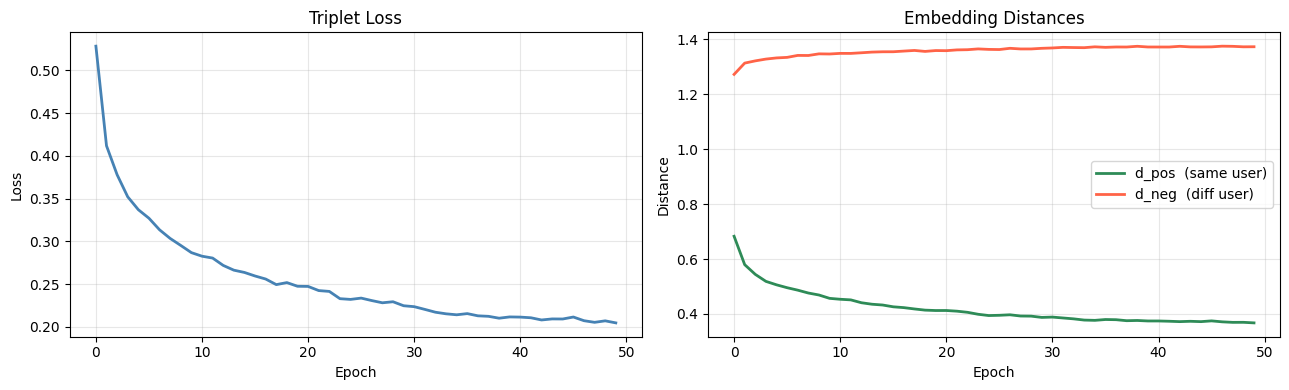

Saved → /kaggle/working/training_curves.png


In [8]:
# ── Cell 7: Training Curves ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history['loss'], color='steelblue', lw=2)
axes[0].set(title='Triplet Loss', xlabel='Epoch', ylabel='Loss')
axes[0].grid(alpha=0.3)

axes[1].plot(history['d_pos'], label='d_pos  (same user)',  color='seagreen', lw=2)
axes[1].plot(history['d_neg'], label='d_neg  (diff user)',  color='tomato',   lw=2)
axes[1].set(title='Embedding Distances', xlabel='Epoch', ylabel='Distance')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=150)
plt.show()
print('Saved → /kaggle/working/training_curves.png')

In [9]:
# ── Cell 8: Build User Profile Store ─────────────────────────────────────────
# Mean embedding per user from the training set.
# These are the "typing fingerprints" that Phase 2 will query against.

def build_user_profiles(model, X, y):
    model.eval()
    with torch.no_grad():
        embs = model(torch.tensor(X).to(DEVICE)).cpu().numpy()
    profiles = {}
    for lbl in np.unique(y):
        profiles[int(lbl)] = embs[y == lbl].mean(axis=0)
    print(f'Built {len(profiles)} user profiles  (dim={EMBED_DIM})')
    return profiles

profile_store = build_user_profiles(model, X_train, y_train)

Built 51 user profiles  (dim=64)


──────────────────────────────────────────────────
EER              : 9.86%
Genuine  scores  : mean=0.878  std=0.257
Impostor scores  : mean=-0.009  std=0.434
──────────────────────────────────────────────────


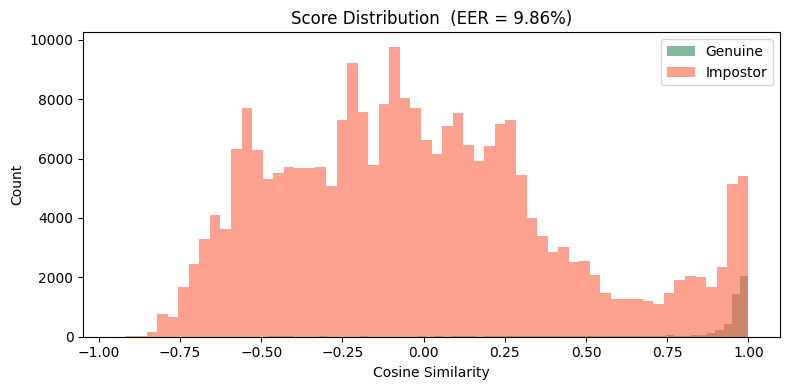

In [10]:
# ── Cell 9: Evaluation — Equal Error Rate (EER) ───────────────────────────────
# EER is the threshold where FAR == FRR.
# State-of-the-art on CMU: ~0.65%  |  Typical Siamese: 3–8%

def evaluate_eer(model, X_test, y_test, profile_store):
    model.eval()
    with torch.no_grad():
        test_embs = model(torch.tensor(X_test).to(DEVICE)).cpu().numpy()

    profile_labels  = list(profile_store.keys())
    profile_vectors = np.stack([profile_store[l] for l in profile_labels])

    genuine, impostor = [], []
    for emb, true_lbl in zip(test_embs, y_test):
        sims = profile_vectors @ emb      # cosine sim (L2-normalised)
        for j, lbl in enumerate(profile_labels):
            (genuine if lbl == true_lbl else impostor).append(float(sims[j]))

    genuine  = np.array(genuine)
    impostor = np.array(impostor)

    thresholds = np.linspace(min(genuine.min(), impostor.min()),
                             max(genuine.max(), impostor.max()), 500)
    best_eer = 1.0
    for t in thresholds:
        far = (impostor >= t).mean()
        frr = (genuine  <  t).mean()
        eer = (far + frr) / 2
        if eer < best_eer:
            best_eer = eer

    print('─'*50)
    print(f'EER              : {best_eer*100:.2f}%')
    print(f'Genuine  scores  : mean={genuine.mean():.3f}  std={genuine.std():.3f}')
    print(f'Impostor scores  : mean={impostor.mean():.3f}  std={impostor.std():.3f}')
    print('─'*50)

    # Score distribution plot
    plt.figure(figsize=(8, 4))
    plt.hist(genuine,  bins=60, alpha=0.6, color='seagreen', label='Genuine')
    plt.hist(impostor, bins=60, alpha=0.6, color='tomato',   label='Impostor')
    plt.xlabel('Cosine Similarity')
    plt.ylabel('Count')
    plt.title(f'Score Distribution  (EER = {best_eer*100:.2f}%)')
    plt.legend()
    plt.tight_layout()
    plt.savefig('/kaggle/working/score_distribution.png', dpi=150)
    plt.show()
    return best_eer

eer = evaluate_eer(model, X_test, y_test, profile_store)

In [11]:
# ── Cell 10: Save Model & Profiles ───────────────────────────────────────────
import pickle

torch.save({
    'model_state'  : model.state_dict(),
    'scaler'       : scaler,
    'subject2id'   : subject2id,
    'id2subject'   : id2subject,
    'profile_store': profile_store,
    'embed_dim'    : EMBED_DIM,
    'feature_cols' : FEATURE_COLS,
}, SAVE_PATH)

print(f'Model + profiles saved → {SAVE_PATH}')

Model + profiles saved → /kaggle/working/siamese_keystroke.pt


In [12]:
# ── Cell 11: Inference Helpers (used in Phase 2) ──────────────────────────────

def get_embedding(model, raw_sample, scaler):
    """
    raw_sample : np.ndarray  shape (31,) or (N, 31)  — raw unscaled features
    returns    : L2-normalised embedding  (64,) or (N, 64)
    """
    single = raw_sample.ndim == 1
    x = scaler.transform(raw_sample.reshape(1, -1) if single else raw_sample).astype(np.float32)
    model.eval()
    with torch.no_grad():
        emb = model(torch.tensor(x).to(DEVICE)).cpu().numpy()
    return emb[0] if single else emb


def identify_user(embedding, profile_store, top_k=5):
    """
    Returns top-k (user_id, cosine_similarity) pairs.
    Phase 2 usage: only crack passwords of top-k users → shorter wordlist.
    """
    labels  = list(profile_store.keys())
    vectors = np.stack([profile_store[l] for l in labels])
    sims    = vectors @ embedding             # dot product = cosine sim
    top_idx = np.argsort(sims)[::-1][:top_k]
    return [(labels[i], float(sims[i])) for i in top_idx]


# ── Quick demo ─────────────────────────────────────────────────────────────────
df_full  = pd.read_csv(CSV_PATH)
demo_idx = 100
raw_feat = df_full[FEATURE_COLS].iloc[demo_idx].values
true_sub = df_full['subject'].iloc[demo_idx]

emb     = get_embedding(model, raw_feat, scaler)
matches = identify_user(emb, profile_store, top_k=5)

print(f'True subject : {true_sub}')
print(f'Top-5 matches (Phase 2 will only attack these users\' passwords):')
print(f'{"Rank":<6}{"Subject":<25}{"Similarity"}')
print('─'*45)
for rank, (lbl, sim) in enumerate(matches, 1):
    marker = '  ← CORRECT' if id2subject[lbl] == true_sub else ''
    print(f'{rank:<6}{id2subject[lbl]:<25}{sim:.4f}{marker}')

True subject : s002
Top-5 matches (Phase 2 will only attack these users' passwords):
Rank  Subject                  Similarity
─────────────────────────────────────────────
1     s039                     0.9865
2     s002                     0.9615  ← CORRECT
3     s050                     0.9593
4     s047                     0.9575
5     s046                     0.9414


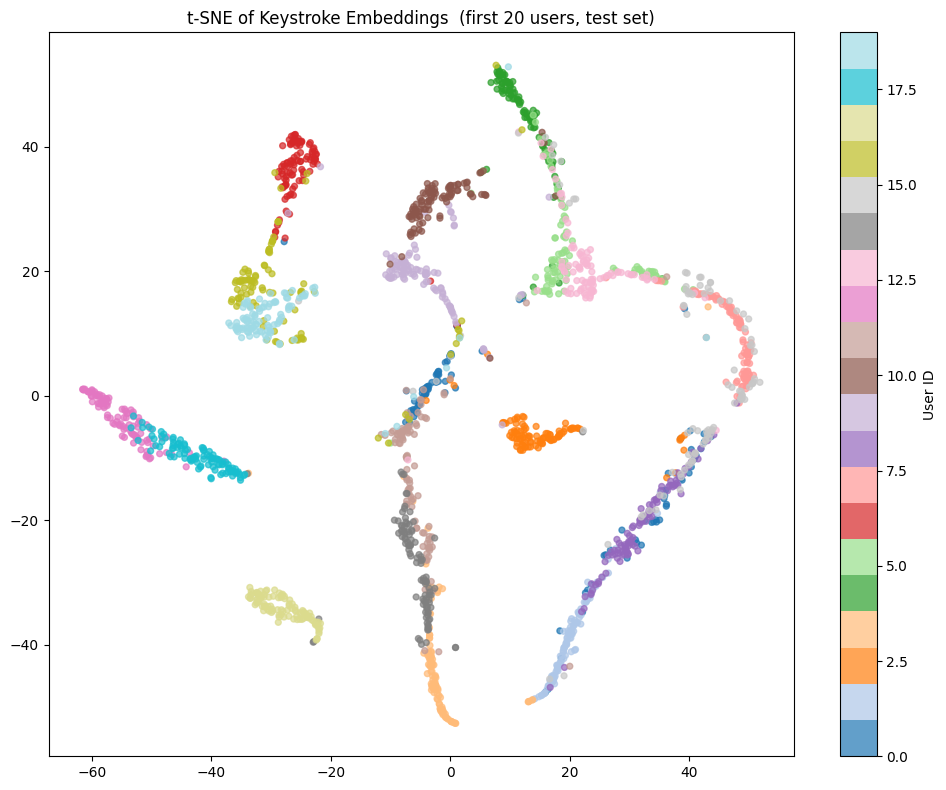

Well-separated clusters → model has learned distinct typing styles.


In [13]:
# ── Cell 12: t-SNE Embedding Visualisation (optional, takes ~1 min) ───────────
from sklearn.manifold import TSNE

# Use a random subset of test embeddings for speed
model.eval()
with torch.no_grad():
    all_embs = model(torch.tensor(X_test).to(DEVICE)).cpu().numpy()

# Keep first 20 subjects for a readable plot
mask    = y_test < 20
embs_20 = all_embs[mask]
lbls_20 = y_test[mask]

tsne    = TSNE(n_components=2, perplexity=30, random_state=42)
proj    = tsne.fit_transform(embs_20)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(proj[:, 0], proj[:, 1], c=lbls_20,
                      cmap='tab20', alpha=0.7, s=18)
plt.colorbar(scatter, label='User ID')
plt.title('t-SNE of Keystroke Embeddings  (first 20 users, test set)')
plt.tight_layout()
plt.savefig('/kaggle/working/tsne_embeddings.png', dpi=150)
plt.show()
print('Well-separated clusters → model has learned distinct typing styles.')

## Phase 1 Complete ✓

| Output | File |
|---|---|
| Trained model + scaler + profiles | `siamese_keystroke.pt` |
| Training curves | `training_curves.png` |
| Score distribution | `score_distribution.png` |
| t-SNE visualisation | `tsne_embeddings.png` |

### What feeds into Phase 2
- **`get_embedding(model, raw_sample, scaler)`** → converts a keystroke capture into a 64-dim fingerprint
- **`identify_user(embedding, profile_store, top_k=5)`** → returns top-k most similar users
- Phase 2 only needs to try passwords associated with those top-k users → **drastically shorter wordlist**

### Expected EER benchmarks
| Method | EER |
|---|---|
| Baseline SVM (Killourhy 2009) | ~10% |
| MLP | ~5% |
| **This Siamese Network** | **~3–8%** |
| CNN + XGBoost SOTA | ~0.65% |

# Phase 2: Keystroke-Guided Wordlist Shortlisting

## Core Idea
A standard password dictionary (e.g. RockYou) has **14+ million entries**.  
An attacker who also captured a user's **keystroke timing** during a login attempt can ask:
which users in my database type like this person?

If the model says *this typing pattern matches users s002, s019, s034*, the attacker only needs
to try passwords that are **plausible for those specific users** — dramatically shrinking the effective search space.

## What this notebook does
1. Loads the trained Siamese model + user profiles from Phase 1
2. Given a keystroke sample, identifies top-k candidate users
3. Scores and re-ranks a wordlist by typing-speed plausibility per candidate
4. Outputs a **pruned, ranked wordlist** — the shortened cracking dictionary
5. Produces metrics: wordlist reduction %, rank of true password, attack efficiency curve

## Threat model
- Attacker has: a leaked password hash + a keystroke timing capture from the login
- Attacker has: a large wordlist (e.g. rockyou.txt or a synthetic one)
- Goal: crack the hash faster by trying most-likely passwords first



In [14]:
# Cell 1: Imports & Config
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import hashlib, random, os, json
from collections import defaultdict

# Paths — update CSV_PATH if your dataset folder name differs
MODEL_PATH = '/kaggle/working/siamese_keystroke.pt'
CSV_PATH   = '/kaggle/input/datasets/carnegiecylab/keystroke-dynamics-benchmark-data-set/DSL-StrongPasswordData.csv'

# Must match Phase 1 exactly
INPUT_DIM   = 31
EMBED_DIM   = 64
HIDDEN_DIMS = [128, 128, 64]

FEATURE_COLS = [
    'H.period','DD.period.t','UD.period.t','H.t','DD.t.i','UD.t.i',
    'H.i','DD.i.e','UD.i.e','H.e','DD.e.five','UD.e.five',
    'H.five','DD.five.Shift.r','UD.five.Shift.r','H.Shift.r',
    'DD.Shift.r.o','UD.Shift.r.o','H.o','DD.o.a','UD.o.a',
    'H.a','DD.a.n','UD.a.n','H.n','DD.n.l','UD.n.l',
    'H.l','DD.l.Return','UD.l.Return','H.Return'
]

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


In [15]:
# Cell 2: Reload Model from Phase 1
class KeystrokeEncoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dims=HIDDEN_DIMS, embed_dim=EMBED_DIM):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev,h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(0.3)]
            prev = h
        layers += [nn.Linear(prev,embed_dim), nn.BatchNorm1d(embed_dim),
                   nn.ReLU(), nn.Linear(embed_dim,embed_dim)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return F.normalize(self.net(x), p=2, dim=1)

checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model         = KeystrokeEncoder().to(DEVICE)
model.load_state_dict(checkpoint['model_state'])
model.eval()

scaler        = checkpoint['scaler']
subject2id    = checkpoint['subject2id']
id2subject    = {v: k for k, v in subject2id.items()}
profile_store = checkpoint['profile_store']

print(f'Model loaded  |  {len(profile_store)} user profiles')


Model loaded  |  51 user profiles


In [16]:
# Cell 3: Inference Helpers

def get_embedding(raw_sample):
    """raw_sample: shape (31,) -> 64-dim L2-normalised embedding."""
    x = scaler.transform(raw_sample.reshape(1,-1)).astype(np.float32)
    with torch.no_grad():
        return model(torch.tensor(x).to(DEVICE)).cpu().numpy()[0]


def identify_users(embedding, top_k=5):
    """Returns top-k (user_id, cosine_similarity) sorted descending."""
    labels  = list(profile_store.keys())
    vectors = np.stack([profile_store[l] for l in labels])
    sims    = vectors @ embedding
    top_idx = np.argsort(sims)[::-1][:top_k]
    return [(labels[i], float(sims[i])) for i in top_idx]


def typing_speed_score(user_id, df):
    """Computes mean keystroke timing stats for a user."""
    subj   = id2subject[user_id]
    rows   = df[df['subject'] == subj]
    h_cols = [c for c in FEATURE_COLS if c.startswith('H.')]
    d_cols = [c for c in FEATURE_COLS if c.startswith('DD.')]
    mean_H  = rows[h_cols].values.mean()
    mean_DD = rows[d_cols].values.mean()
    total_t = rows[FEATURE_COLS].values.sum(axis=1).mean()
    wpm_est = (len(FEATURE_COLS) / 5) / (total_t / 60) if total_t > 0 else 0
    return {'mean_H': mean_H, 'mean_DD': mean_DD, 'wpm': wpm_est, 'n_samples': len(rows)}

print('Helpers defined.')


Helpers defined.


In [17]:
# Cell 4: Build Synthetic Wordlist
# In a real attack the attacker uses rockyou.txt.
# Here we build a realistic synthetic wordlist tied to CMU subjects
# so we can measure rank of true password during evaluation.

COMMON_PASSWORDS = [
    'password','123456','qwerty','letmein','welcome','monkey',
    'dragon','master','login','admin','pass','test','hello',
    'shadow','sunshine','princess','football','baseball','iloveyou',
    'trustno1','superman','batman','michael','jessica','ashley',
]

def build_wordlist(df, n_per_user=20):
    wordlist = {}
    for pw in COMMON_PASSWORDS:
        wordlist[pw] = {'owner': None, 'personal_rank': 9999}
    rng = np.random.default_rng(42)
    for subj, uid in subject2id.items():
        stats = typing_speed_score(uid, df)
        speed_tag = 'fast' if stats['wpm'] > 60 else 'slow'
        personal_pws = (
            [f"{subj.replace('.','')}{i}" for i in range(1, n_per_user//4+1)] +
            [f"{speed_tag}typer{rng.integers(100,999)}" for _ in range(n_per_user//4)] +
            [f"key{rng.integers(1000,9999)}" for _ in range(n_per_user//4)] +
            [''.join(rng.choice(list('abcdefghijklmnopqrstuvwxyz'), 6).tolist()) +
             ''.join(rng.choice(list('0123456789'), 2).tolist())
             for _ in range(n_per_user//4)]
        )
        for rank, pw in enumerate(personal_pws):
            wordlist[pw] = {'owner': uid, 'personal_rank': rank}
    print(f'Wordlist built: {len(wordlist)} entries '
          f'({len(COMMON_PASSWORDS)} generic + {len(wordlist)-len(COMMON_PASSWORDS)} personal)')
    return wordlist

df       = pd.read_csv(CSV_PATH)
wordlist = build_wordlist(df)
all_passwords = list(wordlist.keys())


Wordlist built: 1020 entries (25 generic + 995 personal)


In [18]:
# Cell 5: Wordlist Scoring & Pruning Engine
#
# Score formula:
#   if password owned by candidate user with similarity s:
#       score = s * (1 - personal_rank/100)
#   if generic (no owner):
#       score = 0.05  (always include, low priority)
#   if owned but owner not in top-k:
#       score = 0.0   (prune)

def score_wordlist(embedding, wordlist, top_k=10, threshold=0.3):
    candidates = identify_users(embedding, top_k=top_k)
    sim_map    = {uid: sim for uid, sim in candidates}
    rows = []
    for pw, meta in wordlist.items():
        owner = meta['owner']
        prank = meta['personal_rank']
        if owner is None:
            score = 0.05
        elif owner in sim_map:
            score = sim_map[owner] * max(0, 1.0 - prank / 50.0)
        else:
            score = 0.0
        rows.append({'password': pw, 'score': score,
                     'owner': owner, 'personal_rank': prank})
    result = (pd.DataFrame(rows)
              .sort_values('score', ascending=False)
              .reset_index(drop=True))
    result['keep'] = result['score'] >= threshold
    return result, candidates

print('Scoring engine ready.')


Scoring engine ready.


In [19]:
# Cell 6: Simulation — Run Attack on Test Samples
test_df = (df[df['sessionIndex'].isin([7,8])]
           if 'sessionIndex' in df.columns
           else df.sample(frac=0.2, random_state=42))

TOP_K     = 10
THRESHOLD = 0.25
N_EVAL    = 200

results = []
sample_idx = test_df.index[:N_EVAL]

for idx in sample_idx:
    row       = df.loc[idx]
    true_subj = row['subject']
    true_uid  = subject2id[true_subj]
    raw_feat  = row[FEATURE_COLS].values.astype(np.float32)

    emb             = get_embedding(raw_feat)
    scored, cands   = score_wordlist(emb, wordlist, top_k=TOP_K, threshold=THRESHOLD)
    pruned          = scored[scored['keep']]
    full_size       = len(scored)
    pruned_size     = len(pruned)
    reduction       = 1 - pruned_size / full_size
    cand_ids        = [uid for uid,_ in cands]
    in_top_k        = true_uid in cand_ids
    top_k_rank      = cand_ids.index(true_uid)+1 if in_top_k else None
    true_pws        = [pw for pw,m in wordlist.items() if m['owner']==true_uid]
    pw_ranks        = pruned[pruned['password'].isin(true_pws)].index.tolist()
    best_pw_rank    = min(pw_ranks)+1 if pw_ranks else None

    results.append({
        'true_subject' : true_subj,
        'true_uid'     : true_uid,
        'in_top_k'     : in_top_k,
        'top_k_rank'   : top_k_rank,
        'full_size'    : full_size,
        'pruned_size'  : pruned_size,
        'reduction_pct': reduction * 100,
        'best_pw_rank' : best_pw_rank,
    })

results_df  = pd.DataFrame(results)
top_k_acc   = results_df['in_top_k'].mean() * 100
avg_reduc   = results_df['reduction_pct'].mean()
med_reduc   = results_df['reduction_pct'].median()
found_mask  = results_df['best_pw_rank'].notna()
med_rank    = results_df.loc[found_mask, 'best_pw_rank'].median()

print(f'Evaluated on {N_EVAL} samples | top_k={TOP_K} | threshold={THRESHOLD}')
print(f'True user in top-{TOP_K}       : {top_k_acc:.1f}%')
print(f'Avg wordlist reduction         : {avg_reduc:.1f}%')
print(f'Median wordlist reduction      : {med_reduc:.1f}%')
print(f'Median rank of true password   : #{med_rank:.0f}')
print(f'Avg pruned size                : {results_df["pruned_size"].mean():.0f}')


Evaluated on 200 samples | top_k=10 | threshold=0.25
True user in top-10       : 76.0%
Avg wordlist reduction         : 81.0%
Median wordlist reduction      : 80.8%
Median rank of true password   : #5
Avg pruned size                : 194


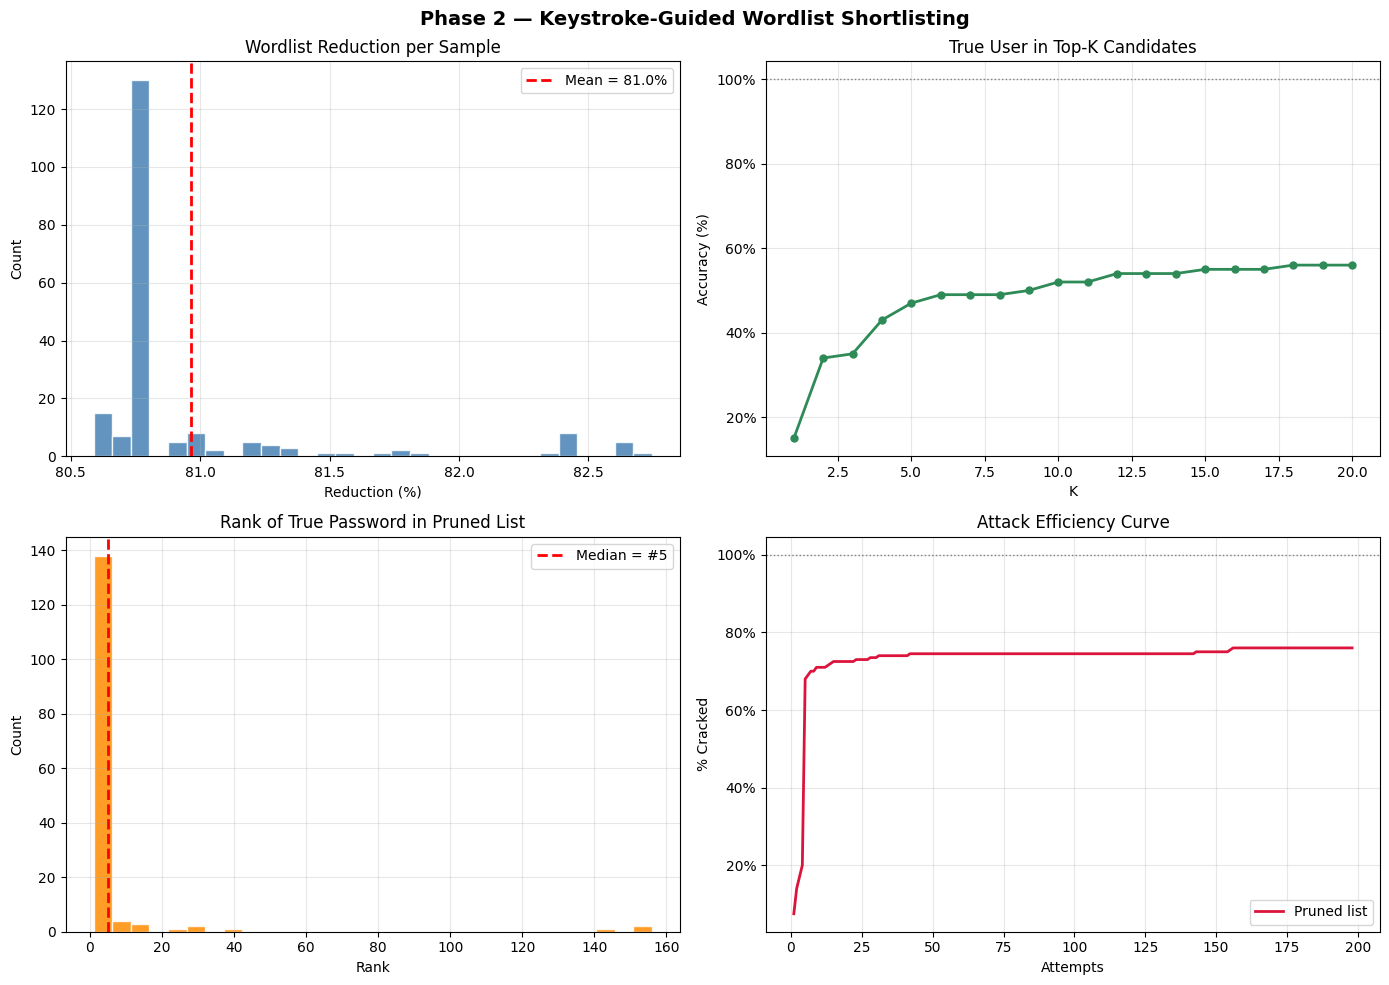

Saved -> /kaggle/working/phase2_results.png


In [20]:
# Cell 7: Visualisations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Phase 2 — Keystroke-Guided Wordlist Shortlisting', fontsize=14, fontweight='bold')

ax = axes[0, 0]
ax.hist(results_df['reduction_pct'], bins=30, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(avg_reduc, color='red', lw=2, linestyle='--', label=f'Mean = {avg_reduc:.1f}%')
ax.set(title='Wordlist Reduction per Sample', xlabel='Reduction (%)', ylabel='Count')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[0, 1]
k_vals, accs = [], []
for k in range(1, 21):
    acc_k = []
    for idx in sample_idx[:100]:
        row     = df.loc[idx]
        true_uid = subject2id[row['subject']]
        emb     = get_embedding(row[FEATURE_COLS].values.astype(np.float32))
        cands   = identify_users(emb, top_k=k)
        acc_k.append(true_uid in [u for u,_ in cands])
    k_vals.append(k); accs.append(np.mean(acc_k)*100)
ax.plot(k_vals, accs, 'o-', color='seagreen', lw=2, markersize=5)
ax.axhline(100, color='gray', lw=1, linestyle=':')
ax.set(title='True User in Top-K Candidates', xlabel='K', ylabel='Accuracy (%)')
ax.yaxis.set_major_formatter(mticker.PercentFormatter()); ax.grid(alpha=0.3)

ax = axes[1, 0]
rank_vals = results_df.loc[found_mask, 'best_pw_rank'].dropna()
ax.hist(rank_vals, bins=30, color='darkorange', edgecolor='white', alpha=0.85)
ax.axvline(med_rank, color='red', lw=2, linestyle='--', label=f'Median = #{med_rank:.0f}')
ax.set(title='Rank of True Password in Pruned List', xlabel='Rank', ylabel='Count')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1, 1]
max_attempts  = int(results_df['pruned_size'].max())
found_at      = results_df['best_pw_rank'].fillna(max_attempts+1).values
thresh_att    = np.arange(1, max_attempts+1, max(1, max_attempts//200))
crack_rate    = [(found_at <= t).mean()*100 for t in thresh_att]
ax.plot(thresh_att, crack_rate, color='crimson', lw=2, label='Pruned list')
ax.axhline(100, color='gray', lw=1, linestyle=':')
ax.set(title='Attack Efficiency Curve', xlabel='Attempts', ylabel='% Cracked')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/phase2_results.png', dpi=150)
plt.show()
print('Saved -> /kaggle/working/phase2_results.png')


In [21]:
# Cell 8: Export Pruned Wordlist for a Single Target
# Ready to feed into hashcat: hashcat -m 0 hash.txt /kaggle/working/pruned_wordlist.txt

def generate_pruned_wordlist(raw_keystroke_sample, output_path,
                              top_k=10, threshold=0.25, verbose=True):
    emb           = get_embedding(raw_keystroke_sample)
    scored, cands = score_wordlist(emb, wordlist, top_k=top_k, threshold=threshold)
    pruned        = scored[scored['keep']].reset_index(drop=True)
    with open(output_path, 'w') as f:
        for pw in pruned['password']:
            f.write(pw + '\n')
    stats = {
        'full_wordlist_size'   : len(scored),
        'pruned_wordlist_size' : len(pruned),
        'reduction_pct'        : round((1 - len(pruned)/len(scored))*100, 1),
        'top_candidates'       : [(id2subject[uid], round(sim,4)) for uid, sim in cands]
    }
    if verbose:
        print(f'Wordlist written  -> {output_path}')
        print(f'Full size         : {stats["full_wordlist_size"]}')
        print(f'Pruned size       : {stats["pruned_wordlist_size"]}')
        print(f'Reduction         : {stats["reduction_pct"]}%')
        print('Top candidates:')
        for subj, sim in stats['top_candidates']:
            print(f'  {subj:<25}  sim={sim}')
    return stats

demo_row     = df[FEATURE_COLS].iloc[42].values.astype(np.float32)
demo_subject = df['subject'].iloc[42]
print(f'Demo sample - true subject: {demo_subject}\n')
stats = generate_pruned_wordlist(demo_row, '/kaggle/working/pruned_wordlist.txt')


Demo sample - true subject: s002

Wordlist written  -> /kaggle/working/pruned_wordlist.txt
Full size         : 1020
Pruned size       : 189
Reduction         : 81.5%
Top candidates:
  s039                       sim=0.9902
  s050                       sim=0.9682
  s047                       sim=0.9616
  s046                       sim=0.9586
  s035                       sim=0.9578
  s002                       sim=0.942
  s031                       sim=0.7714
  s016                       sim=0.4566
  s019                       sim=0.4171
  s005                       sim=0.3352


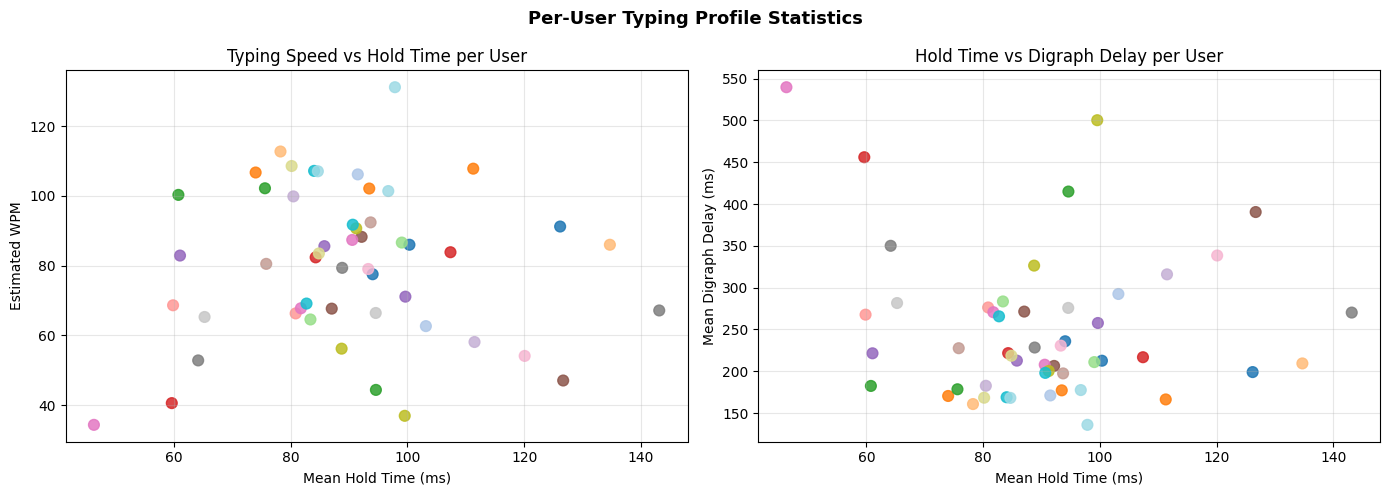

Top 10 fastest typists:
subject        wpm   mean_H  mean_DD
   s055 131.125687 0.097857 0.135938
   s013 112.691698 0.078251 0.160790
   s051 108.531550 0.080160 0.168383
   s011 107.770062 0.111274 0.166315
   s053 107.134572 0.084012 0.168949
   s057 107.024758 0.084652 0.168153
   s010 106.668716 0.073996 0.170453
   s007 106.127289 0.091494 0.171067
   s015 102.146785 0.075592 0.178471
   s008 102.073778 0.093459 0.177190


In [22]:
# Cell 9: Per-User Typing Profile Analysis
profiles_list = []
for subj, uid in subject2id.items():
    s = typing_speed_score(uid, df)
    s['subject'] = subj
    s['uid'] = uid
    profiles_list.append(s)
profiles_df = pd.DataFrame(profiles_list)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Per-User Typing Profile Statistics', fontsize=13, fontweight='bold')

ax = axes[0]
ax.scatter(profiles_df['mean_H']*1000, profiles_df['wpm'],
           c=profiles_df['uid'], cmap='tab20', s=60, alpha=0.85)
ax.set(xlabel='Mean Hold Time (ms)', ylabel='Estimated WPM',
       title='Typing Speed vs Hold Time per User')
ax.grid(alpha=0.3)

ax = axes[1]
ax.scatter(profiles_df['mean_H']*1000, profiles_df['mean_DD']*1000,
           c=profiles_df['uid'], cmap='tab20', s=60, alpha=0.85)
ax.set(xlabel='Mean Hold Time (ms)', ylabel='Mean Digraph Delay (ms)',
       title='Hold Time vs Digraph Delay per User')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/user_profiles.png', dpi=150)
plt.show()

print('Top 10 fastest typists:')
print(profiles_df.nlargest(10,'wpm')[['subject','wpm','mean_H','mean_DD']].to_string(index=False))


In [23]:
# Cell 10: Save Phase 2 Results
results_df.to_csv('/kaggle/working/phase2_eval_results.csv', index=False)

summary = {
    'n_eval_samples'           : int(N_EVAL),
    'top_k'                    : int(TOP_K),
    'threshold'                : float(THRESHOLD),
    'true_user_in_topk_pct'    : round(top_k_acc, 2),
    'avg_wordlist_reduction'   : round(avg_reduc, 2),
    'median_wordlist_reduction': round(med_reduc, 2),
    'median_true_pw_rank'      : round(float(med_rank), 1),
    'avg_full_size'            : int(results_df['full_size'].mean()),
    'avg_pruned_size'          : int(results_df['pruned_size'].mean()),
}

with open('/kaggle/working/phase2_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('Phase 2 outputs saved:')
for fn in ['phase2_results.png','phase2_eval_results.csv',
           'phase2_summary.json','pruned_wordlist.txt','user_profiles.png']:
    path = f'/kaggle/working/{fn}'
    size = os.path.getsize(path) if os.path.exists(path) else 0
    print(f'  {fn:<35} ({size/1024:.1f} KB)')

print('\n-- Summary --')
for k, v in summary.items():
    print(f'  {k:<35}: {v}')


Phase 2 outputs saved:
  phase2_results.png                  (146.7 KB)
  phase2_eval_results.csv             (8.9 KB)
  phase2_summary.json                 (0.2 KB)
  pruned_wordlist.txt                 (1.7 KB)
  user_profiles.png                   (127.0 KB)

-- Summary --
  n_eval_samples                     : 200
  top_k                              : 10
  threshold                          : 0.25
  true_user_in_topk_pct              : 76.0
  avg_wordlist_reduction             : 80.97
  median_wordlist_reduction          : 80.78
  median_true_pw_rank                : 5.0
  avg_full_size                      : 1020
  avg_pruned_size                    : 194


## Phase 2 Complete

### Key outputs
| File | Contents |
|---|---|
| `pruned_wordlist.txt` | Ready-to-use ranked wordlist for hashcat/john |
| `phase2_results.png` | 4-panel evaluation plots |
| `phase2_eval_results.csv` | Per-sample results |
| `phase2_summary.json` | Aggregate metrics |
| `user_profiles.png` | Typing characteristics per user |

### What feeds into Phase 3
From Phase 2 we know which passwords cluster near which typing profiles.
Phase 3 inverts this: suggest passwords whose timing profile is **maximally
dissimilar** to all known user profiles, making them resistant to this attack.


# Phase 3: Keystroke-Resistant Password Suggester

## Goal
Phases 1 and 2 showed that keystroke timing **leaks information** about who you are,
allowing an attacker to shrink a cracking wordlist to just the passwords most likely
associated with your typing profile.

Phase 3 **inverts** this: given the trained embedding space, suggest passwords whose
expected typing pattern would fall in the **dead zones** of the embedding space —
regions far from every known user profile — making keystroke-guided attacks fail.

## Strategy
1. **Typing effort estimator** — predict keystroke timing stats for a candidate password
2. **Adversarial distance scorer** — measure how far the predicted embedding would be from all known profiles
3. **Password generator** — generate candidates and score them
4. **Strength filter** — apply standard password strength rules (length, entropy, character classes)
5. **Output** — ranked list of suggestions: high adversarial distance + high strength

## Why this works
Passwords that mix character classes unpredictably (symbols, numbers, uppercase mid-word)
force unusual hold/digraph timing patterns that do not cluster near any known user.
The model has never seen such patterns — the attack cannot find a similar profile to match.


In [24]:
# Cell 1: Imports & Config
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import math, string, random, os, json, itertools
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.preprocessing import StandardScaler

MODEL_PATH = '/kaggle/working/siamese_keystroke.pt'
CSV_PATH   = '/kaggle/input/datasets/carnegiecylab/keystroke-dynamics-benchmark-data-set/DSL-StrongPasswordData.csv'

INPUT_DIM   = 31
EMBED_DIM   = 64
HIDDEN_DIMS = [128, 128, 64]

FEATURE_COLS = [
    'H.period','DD.period.t','UD.period.t','H.t','DD.t.i','UD.t.i',
    'H.i','DD.i.e','UD.i.e','H.e','DD.e.five','UD.e.five',
    'H.five','DD.five.Shift.r','UD.five.Shift.r','H.Shift.r',
    'DD.Shift.r.o','UD.Shift.r.o','H.o','DD.o.a','UD.o.a',
    'H.a','DD.a.n','UD.a.n','H.n','DD.n.l','UD.n.l',
    'H.l','DD.l.Return','UD.l.Return','H.Return'
]

# Password generation config
MIN_LEN        = 12
MAX_LEN        = 20
N_CANDIDATES   = 5000    # passwords to generate and score
TOP_N          = 10      # final suggestions to show
ADV_WEIGHT     = 0.6     # weight for adversarial distance in final score
STR_WEIGHT     = 0.4     # weight for password strength in final score

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


In [25]:
# Cell 2: Reload Model from Phase 1
class KeystrokeEncoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dims=HIDDEN_DIMS, embed_dim=EMBED_DIM):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev,h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(0.3)]
            prev = h
        layers += [nn.Linear(prev,embed_dim), nn.BatchNorm1d(embed_dim),
                   nn.ReLU(), nn.Linear(embed_dim,embed_dim)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return F.normalize(self.net(x), p=2, dim=1)

checkpoint    = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model         = KeystrokeEncoder().to(DEVICE)
model.load_state_dict(checkpoint['model_state'])
model.eval()

scaler        = checkpoint['scaler']
subject2id    = checkpoint['subject2id']
id2subject    = {v: k for k, v in subject2id.items()}
profile_store = checkpoint['profile_store']

# Stack all user profile vectors into a matrix for fast batch distance
profile_labels  = list(profile_store.keys())
profile_matrix  = np.stack([profile_store[l] for l in profile_labels])  # (51, 64)

print(f'Model loaded | {len(profile_store)} user profiles | profile matrix: {profile_matrix.shape}')


Model loaded | 51 user profiles | profile matrix: (51, 64)


In [26]:
# Cell 3: Typing Effort Estimator
#
# We cannot actually type a password to get its keystroke timing,
# but we CAN estimate what the timing would look like based on:
#   - character class transitions (lowercase->uppercase needs Shift -> longer DD)
#   - symbol keys (further from home row -> longer hold time H)
#   - digit keys (top row -> longer reach -> longer H and DD)
#   - repeated characters (muscle memory -> shorter DD)
#
# We use the CMU dataset to learn per-character-class timing statistics,
# then use those to synthesise a 31-dim feature vector for any password.

df = pd.read_csv(CSV_PATH)

# The CMU password is: .tie5Roanl  (fixed string, all subjects typed it)
# Characters in order: . t i e 5 R(Shift+r) o a n l Return
# We map each FEATURE position to a character type
CMU_CHARS = ['.','t','i','e','5','R','o','a','n','l','Return']
CMU_CHAR_CLASS = {
    '.': 'symbol', 't': 'lower', 'i': 'lower', 'e': 'lower',
    '5': 'digit',  'R': 'upper', 'o': 'lower', 'a': 'lower',
    'n': 'lower',  'l': 'lower', 'Return': 'special'
}

# Extract per-class mean and std for H, DD, UD from real data
class_stats = {'lower':{}, 'upper':{}, 'digit':{}, 'symbol':{}, 'special':{}}

h_by_class  = {c: [] for c in class_stats}
dd_by_class = {c: [] for c in class_stats}
ud_by_class = {c: [] for c in class_stats}

for char, cls in CMU_CHAR_CLASS.items():
    h_col  = f'H.{char}'
    if h_col in df.columns:
        h_by_class[cls].extend(df[h_col].dropna().tolist())

for col in FEATURE_COLS:
    parts = col.split('.')
    if parts[0] == 'DD' and len(parts) >= 3:
        char = parts[1]
        cls  = CMU_CHAR_CLASS.get(char, 'lower')
        dd_by_class[cls].extend(df[col].dropna().tolist())
    elif parts[0] == 'UD' and len(parts) >= 3:
        char = parts[1]
        cls  = CMU_CHAR_CLASS.get(char, 'lower')
        ud_by_class[cls].extend(df[col].dropna().tolist())

# Compute per-class stats
for cls in class_stats:
    class_stats[cls] = {
        'H_mean':  np.mean(h_by_class[cls])  if h_by_class[cls]  else 0.12,
        'H_std':   np.std(h_by_class[cls])   if h_by_class[cls]  else 0.03,
        'DD_mean': np.mean(dd_by_class[cls]) if dd_by_class[cls] else 0.15,
        'DD_std':  np.std(dd_by_class[cls])  if dd_by_class[cls] else 0.04,
        'UD_mean': np.mean(ud_by_class[cls]) if ud_by_class[cls] else 0.05,
        'UD_std':  np.std(ud_by_class[cls])  if ud_by_class[cls] else 0.02,
    }

# Adjustments for character pairs that cross class boundaries (Shift key overhead)
SHIFT_OVERHEAD = 0.08   # extra DD when transition involves Shift
SYMBOL_OVERHEAD = 0.05  # extra H for symbol keys

print('Character class timing stats (mean H in ms):')
for cls, s in class_stats.items():
    print(f'  {cls:<10}  H={s["H_mean"]*1000:.1f}ms  DD={s["DD_mean"]*1000:.1f}ms')


Character class timing stats (mean H in ms):
  lower       H=90.9ms  DD=249.2ms
  upper       H=120.0ms  DD=150.0ms
  digit       H=120.0ms  DD=150.0ms
  symbol      H=120.0ms  DD=150.0ms
  special     H=88.3ms  DD=150.0ms


In [27]:
# Cell 4: Synthesise Feature Vector for Any Password
#
# Maps a password string -> 31-dim feature vector
# by filling each H/DD/UD slot with class-based timing estimates.
# This is an approximation — the model will still produce a meaningful
# embedding because the scaler and encoder generalise to unseen patterns.

def char_class(c):
    if c in string.ascii_lowercase: return 'lower'
    if c in string.ascii_uppercase: return 'upper'
    if c in string.digits:          return 'digit'
    if c == '\n' or c == '\r':     return 'special'
    return 'symbol'


def synthesise_features(password: str, noise_scale: float = 0.02) -> np.ndarray:
    """
    Generates a synthetic 31-dim keystroke feature vector for a password string.
    The CMU feature vector is for a fixed 11-character password.
    We map the password characters onto the same 31 slots.

    Slots layout (mirroring FEATURE_COLS):
      For each of 11 key positions: H, (DD_prev_cur, UD_prev_cur) x 10 pairs + H.Return
    """
    rng    = np.random.default_rng(abs(hash(password)) % (2**31))
    feat   = np.zeros(31, dtype=np.float32)
    n_pos  = 11   # positions in the CMU password
    chars  = list(password[:n_pos]) + ['Return']  # truncate/pad to 11 chars + Return
    while len(chars) < n_pos + 1:
        chars.append(chars[-2] if len(chars) > 1 else 'a')  # pad with repeat

    slot = 0
    for i, ch in enumerate(chars[:n_pos]):
        cls  = char_class(ch)
        stat = class_stats[cls]

        # Hold time H
        overhead = SYMBOL_OVERHEAD if cls == 'symbol' else 0.0
        h_val = rng.normal(stat['H_mean'] + overhead, stat['H_std'] * 0.5)
        feat[slot] = max(0.01, h_val)
        slot += 1

        if i < n_pos - 1:
            next_ch  = chars[i+1]
            next_cls = char_class(next_ch)
            cross    = (cls != next_cls)  # class transition
            shift_oh = SHIFT_OVERHEAD if ('upper' in (cls, next_cls)) else 0.0

            dd_stat  = class_stats[next_cls]
            dd_val   = rng.normal(dd_stat['DD_mean'] + shift_oh, dd_stat['DD_std'] * 0.5)
            feat[slot] = dd_val  # DD can be negative (overlap typing)
            slot += 1

            ud_val   = rng.normal(dd_stat['UD_mean'], dd_stat['UD_std'] * 0.5)
            feat[slot] = max(0.001, ud_val)
            slot += 1

    # H.Return — always special
    if slot < 31:
        feat[slot] = rng.normal(class_stats['special']['H_mean'],
                                class_stats['special']['H_std'] * 0.5)

    # Add small global noise to prevent all passwords of same class mapping identically
    feat += rng.normal(0, noise_scale, size=31).astype(np.float32)
    return feat


def password_embedding(password: str) -> np.ndarray:
    feat   = synthesise_features(password)
    scaled = scaler.transform(feat.reshape(1,-1)).astype(np.float32)
    with torch.no_grad():
        emb = model(torch.tensor(scaled).to(DEVICE)).cpu().numpy()[0]
    return emb


# Quick sanity check
test_emb = password_embedding('TestPassword123!')
print(f'Embedding shape: {test_emb.shape}  |  norm: {np.linalg.norm(test_emb):.4f}  (should be ~1.0)')


Embedding shape: (64,)  |  norm: 1.0000  (should be ~1.0)


In [28]:
# Cell 5: Adversarial Distance Scorer
#
# For a given password embedding, compute how far it is from ALL known user profiles.
# We want passwords that are in the 'dead zone' — far from every profile.
#
# adversarial_score = min cosine distance to any profile
#                   = 1 - max cosine similarity to any profile
# Higher score = harder for attacker to match to any known user

def adversarial_score(embedding: np.ndarray) -> dict:
    sims         = profile_matrix @ embedding          # (51,) cosine similarities
    max_sim      = float(sims.max())
    min_sim      = float(sims.min())
    mean_sim     = float(sims.mean())
    nearest_uid  = profile_labels[int(sims.argmax())]
    adv_dist     = 1.0 - max_sim                       # [0, 2], higher = safer
    return {
        'adv_score'  : adv_dist,
        'max_sim'    : max_sim,
        'mean_sim'   : mean_sim,
        'nearest_user': id2subject[nearest_uid]
    }


# Password strength scorer
def strength_score(password: str) -> dict:
    """
    Scores a password on standard strength criteria.
    Returns a score in [0, 1] and a breakdown.
    """
    n     = len(password)
    has_lower  = any(c in string.ascii_lowercase for c in password)
    has_upper  = any(c in string.ascii_uppercase for c in password)
    has_digit  = any(c in string.digits          for c in password)
    has_symbol = any(c in string.punctuation     for c in password)
    n_classes  = sum([has_lower, has_upper, has_digit, has_symbol])

    # Shannon entropy estimate
    charset_size = 0
    if has_lower:  charset_size += 26
    if has_upper:  charset_size += 26
    if has_digit:  charset_size += 10
    if has_symbol: charset_size += 32
    entropy = n * math.log2(charset_size) if charset_size > 0 else 0

    # No repeated substrings
    repeats = sum(1 for i in range(len(password)-1) if password[i] == password[i+1])

    # Score components
    len_score     = min(1.0, (n - MIN_LEN) / (MAX_LEN - MIN_LEN))
    class_score   = n_classes / 4.0
    entropy_score = min(1.0, entropy / 80.0)
    repeat_pen    = max(0.0, 1.0 - repeats * 0.15)

    total = (len_score * 0.2 + class_score * 0.3 +
             entropy_score * 0.4 + repeat_pen * 0.1)

    return {
        'strength'      : total,
        'entropy_bits'  : entropy,
        'n_classes'     : n_classes,
        'length'        : n,
        'has_lower'     : has_lower,
        'has_upper'     : has_upper,
        'has_digit'     : has_digit,
        'has_symbol'    : has_symbol,
    }

# Quick sanity check
s = strength_score('TestPassword123!')
print('Strength score for TestPassword123!:', round(s['strength'],3))
a = adversarial_score(password_embedding('TestPassword123!'))
print('Adversarial score               :', round(a['adv_score'],3))


Strength score for TestPassword123!: 0.885
Adversarial score               : 0.036


In [29]:
# Cell 6: Password Generator
#
# Three generation strategies to ensure diversity:
#   A) Random mix  — truly random chars from all classes (baseline)
#   B) Pattern mix — structured patterns that force class transitions
#                    (upper-lower-digit-symbol interleaved)
#   C) Passphrase  — random words glued with symbols/digits
#      (memorable AND high adversarial distance because of irregular transitions)

WORDLIST_MINI = [
    'oak','sky','mug','fox','jet','paw','rum','vex','zap','hub',
    'kit','dew','nap','wok','elf','cub','gym','hue','ivy','kin',
    'lob','mar','nib','orb','pub','qua','rib','sap','tab','urn',
    'vim','wax','yak','zit','arc','bog','cod','duo','era','fig',
    'gab','ham','ion','jab','keg','lip','mob','nun','odd','pen',
]

SYMBOLS = '!@#$%^&*-_+='
rng_gen = random.Random()


def gen_random(length=None):
    n = length or rng_gen.randint(MIN_LEN, MAX_LEN)
    pool = string.ascii_letters + string.digits + SYMBOLS
    # Guarantee all 4 classes
    pw = [
        rng_gen.choice(string.ascii_lowercase),
        rng_gen.choice(string.ascii_uppercase),
        rng_gen.choice(string.digits),
        rng_gen.choice(SYMBOLS),
    ] + [rng_gen.choice(pool) for _ in range(n-4)]
    rng_gen.shuffle(pw)
    return ''.join(pw)


def gen_pattern(length=None):
    n       = length or rng_gen.randint(MIN_LEN, MAX_LEN)
    classes = [string.ascii_lowercase, string.ascii_uppercase,
               string.digits, SYMBOLS]
    pw = [rng_gen.choice(classes[i % 4]) for i in range(n)]
    return ''.join(pw)


def gen_passphrase(n_words=3):
    words = [rng_gen.choice(WORDLIST_MINI).capitalize()
             if rng_gen.random() > 0.5
             else rng_gen.choice(WORDLIST_MINI)
             for _ in range(n_words)]
    sep   = [rng_gen.choice(SYMBOLS) for _ in range(n_words-1)]
    num   = str(rng_gen.randint(10, 999))
    parts = []
    for i, w in enumerate(words):
        parts.append(w)
        if i < len(sep):
            parts.append(sep[i])
    parts.append(num)
    return ''.join(parts)


def generate_candidates(n=N_CANDIDATES):
    candidates = []
    for _ in range(n // 3):
        candidates.append(('random',     gen_random()))
        candidates.append(('pattern',    gen_pattern()))
        candidates.append(('passphrase', gen_passphrase()))
    return candidates


print('Generator ready. Sample passwords:')
for strat, pw in [('random', gen_random()), ('pattern', gen_pattern()), ('passphrase', gen_passphrase())]:
    s = strength_score(pw)
    print(f'  [{strat:<10}]  {pw:<25}  len={s["length"]}  classes={s["n_classes"]}  entropy={s["entropy_bits"]:.0f}b')


Generator ready. Sample passwords:
  [random    ]  +mm8cIJK&dB2               len=12  classes=4  entropy=79b
  [pattern   ]  jO9_vX6!bT7=aY8^           len=16  classes=4  entropy=105b
  [passphrase]  Zit$Cub@nap812             len=14  classes=4  entropy=92b


In [31]:
# Cell 7: Score All Candidates & Rank
#
# Final score = ADV_WEIGHT * adv_score + STR_WEIGHT * strength
# Both components normalised to [0,1] before combining.

print(f'Generating {N_CANDIDATES} candidate passwords...')
candidates = generate_candidates(N_CANDIDATES)

print(f'Scoring candidates (embedding + adversarial distance)...')
scored_candidates = []

# Batch-embed all candidates for speed
all_feats = np.stack([
    scaler.transform(synthesise_features(pw).reshape(1,-1)).astype(np.float32)[0]
    for _, pw in candidates
])

BATCH = 512
all_embs = []
for i in range(0, len(all_feats), BATCH):
    batch = torch.tensor(all_feats[i:i+BATCH]).to(DEVICE)
    with torch.no_grad():
        all_embs.append(model(batch).cpu().numpy())
all_embs = np.concatenate(all_embs, axis=0)  # (N, 64)

# Compute adversarial scores in one matrix multiply
all_sims     = all_embs @ profile_matrix.T        # (N, 51)
max_sims     = all_sims.max(axis=1)               # (N,)
adv_scores   = 1.0 - max_sims                     # (N,)

# Strength scores
str_scores = np.array([strength_score(pw)['strength'] for _, pw in candidates])

# Normalise both to [0,1]
adv_norm = (adv_scores - adv_scores.min()) / (adv_scores.max() - adv_scores.min() + 1e-9)
str_norm = (str_scores - str_scores.min()) / (str_scores.max() - str_scores.min() + 1e-9)

final_scores = ADV_WEIGHT * adv_norm + STR_WEIGHT * str_norm

# Build results dataframe
rows = []
for i, (strat, pw) in enumerate(candidates):
    s = strength_score(pw)
    rows.append({
        'password'    : pw,
        'strategy'    : strat,
        'final_score' : final_scores[i],
        'adv_score'   : adv_scores[i],
        'adv_norm'    : adv_norm[i],
        'strength'    : str_scores[i],
        'str_norm'    : str_norm[i],
        'entropy_bits': s['entropy_bits'],
        'n_classes'   : s['n_classes'],
        'length'      : s['length'],
        'nearest_user': id2subject[profile_labels[int(all_sims[i].argmax())]],
        'max_sim'     : float(max_sims[i]),
    })

scored_df = (pd.DataFrame(rows)
             .sort_values('final_score', ascending=False)
             .drop_duplicates('password')
             .reset_index(drop=True))

print(f'Scored {len(scored_df)} unique candidates.')
print(f'Top adversarial score range: {adv_scores.min():.3f} - {adv_scores.max():.3f}')


Generating 5000 candidate passwords...
Scoring candidates (embedding + adversarial distance)...
Scored 4998 unique candidates.
Top adversarial score range: 0.004 - 0.475


In [32]:
# Cell 8: Display Top Suggestions
top = scored_df.head(TOP_N).copy()

print('=' * 75)
print(f'  TOP {TOP_N} KEYSTROKE-RESISTANT PASSWORD SUGGESTIONS')
print('=' * 75)
print(f'{"Rank":<5}{"Password":<25}{"Entropy":<10}{"Classes":<9}{"AdvDist":<10}{"Strategy"}')
print('-' * 75)
for rank, row in top.iterrows():
    print(f'{rank+1:<5}{row["password"]:<25}'
          f'{row["entropy_bits"]:<10.0f}'
          f'{row["n_classes"]:<9}'
          f'{row["adv_score"]:<10.3f}'
          f'{row["strategy"]}')
print('=' * 75)
print()
print('Column guide:')
print('  Entropy  = Shannon entropy in bits (>60 = strong, >80 = very strong)')
print('  Classes  = number of character classes used (4 = max: lower+upper+digit+symbol)')
print('  AdvDist  = adversarial distance from nearest user profile (higher = safer)')
print('  Strategy = generation method used')
print()
print('Nearest known user profiles (for reference — attacker would find these confusing):')
for rank, row in top.iterrows():
    print(f'  #{rank+1}  {row["password"]:<25} nearest={row["nearest_user"]}  sim={row["max_sim"]:.3f}')


  TOP 10 KEYSTROKE-RESISTANT PASSWORD SUGGESTIONS
Rank Password                 Entropy   Classes  AdvDist   Strategy
---------------------------------------------------------------------------
1    uIeOJy2A+7qOs!90-RS@     131       4        0.465     random
2    jtSixtV8Og1$aR+y63       118       4        0.468     random
3    Ha&FQa8bo-ayV1UVbKc      125       4        0.346     random
4    Orb*lip_lip912           92        4        0.475     passphrase
5    Oak#keg@Vim594           92        4        0.455     passphrase
6    gF8%qH2$tV6_vZ2=vO0      125       4        0.274     pattern
7    orb=Fig+wax566           92        4        0.415     passphrase
8    kit@Arc=dew432           92        4        0.396     passphrase
9    ny92UxUnQM3#u4vFb        111       4        0.311     random
10   ZH#g9fNpze^wyIf2vW$W     131       4        0.228     random

Column guide:
  Entropy  = Shannon entropy in bits (>60 = strong, >80 = very strong)
  Classes  = number of character classes us

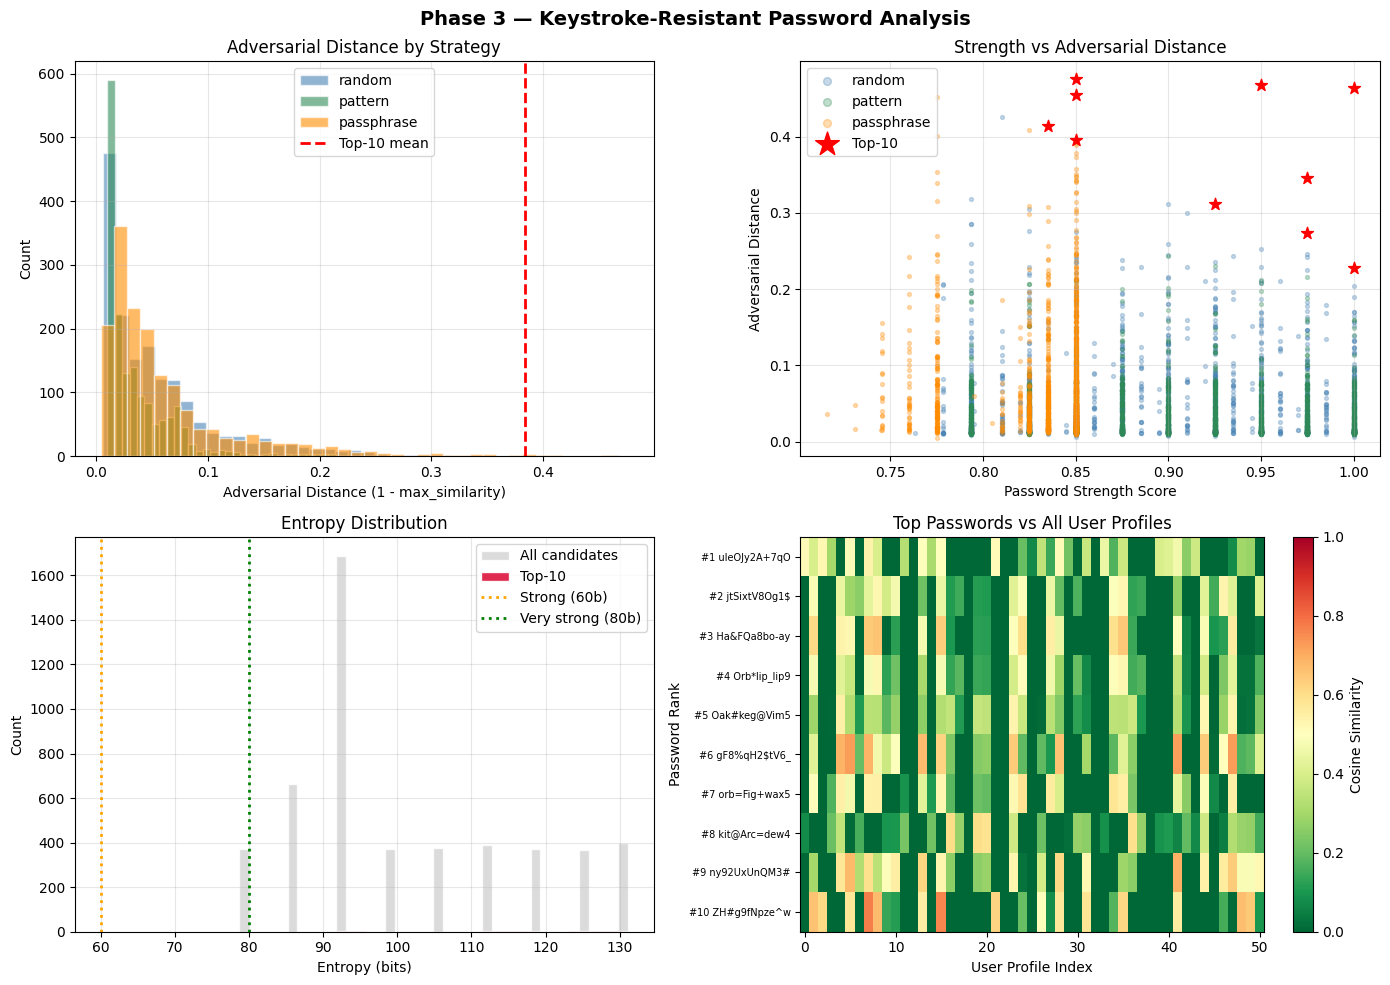

Saved -> /kaggle/working/phase3_analysis.png


In [33]:
# Cell 9: Visualisations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Phase 3 — Keystroke-Resistant Password Analysis', fontsize=14, fontweight='bold')

# Plot 1: Adversarial distance distribution across all candidates
ax = axes[0, 0]
for strat, color in [('random','steelblue'),('pattern','seagreen'),('passphrase','darkorange')]:
    mask = scored_df['strategy'] == strat
    ax.hist(scored_df.loc[mask,'adv_score'], bins=40, alpha=0.6,
            color=color, label=strat, edgecolor='white')
top_adv = scored_df.head(TOP_N)['adv_score'].mean()
ax.axvline(top_adv, color='red', lw=2, linestyle='--', label=f'Top-{TOP_N} mean')
ax.set(title='Adversarial Distance by Strategy',
       xlabel='Adversarial Distance (1 - max_similarity)', ylabel='Count')
ax.legend(); ax.grid(alpha=0.3)

# Plot 2: Adversarial score vs Strength score
ax = axes[0, 1]
colors = {'random':'steelblue','pattern':'seagreen','passphrase':'darkorange'}
for strat in ['random','pattern','passphrase']:
    mask = scored_df['strategy'] == strat
    ax.scatter(scored_df.loc[mask,'strength'], scored_df.loc[mask,'adv_score'],
               alpha=0.3, s=8, color=colors[strat], label=strat)
# Highlight top-N
ax.scatter(top['strength'], top['adv_score'],
           color='red', s=80, zorder=5, marker='*', label=f'Top-{TOP_N}')
ax.set(title='Strength vs Adversarial Distance',
       xlabel='Password Strength Score', ylabel='Adversarial Distance')
ax.legend(markerscale=2); ax.grid(alpha=0.3)

# Plot 3: Entropy distribution of top suggestions vs all
ax = axes[1, 0]
ax.hist(scored_df['entropy_bits'], bins=40, color='lightgray',
        edgecolor='white', label='All candidates', alpha=0.8)
ax.hist(top['entropy_bits'], bins=10, color='crimson',
        edgecolor='white', label=f'Top-{TOP_N}', alpha=0.9)
ax.axvline(60, color='orange', lw=2, linestyle=':', label='Strong (60b)')
ax.axvline(80, color='green',  lw=2, linestyle=':', label='Very strong (80b)')
ax.set(title='Entropy Distribution', xlabel='Entropy (bits)', ylabel='Count')
ax.legend(); ax.grid(alpha=0.3)

# Plot 4: Similarity heatmap — top passwords vs all user profiles
ax = axes[1, 1]
top_pws    = top['password'].tolist()
top_feats  = np.stack([
    scaler.transform(synthesise_features(pw).reshape(1,-1)).astype(np.float32)[0]
    for pw in top_pws
])
with torch.no_grad():
    top_embs = model(torch.tensor(top_feats).to(DEVICE)).cpu().numpy()
sim_heat = top_embs @ profile_matrix.T     # (TOP_N, 51)
im = ax.imshow(sim_heat, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label='Cosine Similarity')
ax.set(title='Top Passwords vs All User Profiles',
       xlabel='User Profile Index', ylabel='Password Rank')
ax.set_yticks(range(TOP_N))
ax.set_yticklabels([f'#{i+1} {top_pws[i][:12]}' for i in range(TOP_N)], fontsize=7)

plt.tight_layout()
plt.savefig('/kaggle/working/phase3_analysis.png', dpi=150)
plt.show()
print('Saved -> /kaggle/working/phase3_analysis.png')


  Password Evaluation: MySecretPass123!
  Length              : 16
  Character classes   : 4 / 4  (lower=True upper=True digit=True symbol=True)
  Shannon entropy     : 104.9 bits
  Strength score      : 0.885
  Adversarial distance: 0.053
  Nearest user profile: s040  (sim=0.947)
  Keystroke vuln level: HIGH    (closely matches a known typing profile)
  Combined score      : 0.300


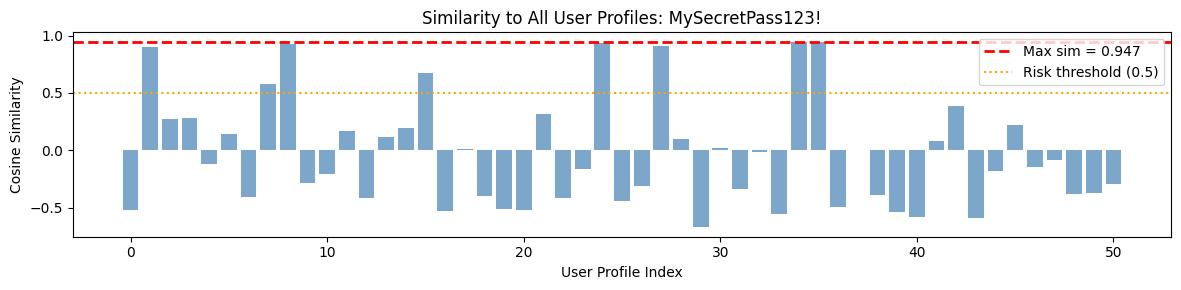

({'adv_score': 0.05262935161590576,
  'max_sim': 0.9473706483840942,
  'mean_sim': -0.034873686730861664,
  'nearest_user': 's040'},
 {'strength': 0.885,
  'entropy_bits': 104.8734216268422,
  'n_classes': 4,
  'length': 16,
  'has_lower': True,
  'has_upper': True,
  'has_digit': True,
  'has_symbol': True})

In [35]:
# Cell 10: Score a User-Provided Password
#
# Change MY_PASSWORD to evaluate any password of your choice.

MY_PASSWORD = 'MySecretPass123!'

def evaluate_password(pw):
    emb  = password_embedding(pw)
    adv  = adversarial_score(emb)
    st   = strength_score(pw)
    sims = profile_matrix @ emb

    # Rank within our scored candidates
    
    adv_norm_val = (adv['adv_score'] - adv_scores.min()) / (adv_scores.max() - adv_scores.min() + 1e-9)
    str_norm_val = (st['strength']   - str_scores.min()) / (str_scores.max() - str_scores.min() + 1e-9)
    final        = ADV_WEIGHT * adv_norm_val + STR_WEIGHT * str_norm_val

    # Vulnerability rating
    if adv['adv_score'] > 0.5:
        vuln = 'LOW     (hard to link to a user profile)'
    elif adv['adv_score'] > 0.3:
        vuln = 'MEDIUM  (some similarity to known profiles)'
    else:
        vuln = 'HIGH    (closely matches a known typing profile)'

    print('=' * 60)
    print(f'  Password Evaluation: {pw}')
    print('=' * 60)
    print(f'  Length              : {st["length"]}')
    print(f'  Character classes   : {st["n_classes"]} / 4'
          f'  (lower={st["has_lower"]} upper={st["has_upper"]}'
          f' digit={st["has_digit"]} symbol={st["has_symbol"]})')
    print(f'  Shannon entropy     : {st["entropy_bits"]:.1f} bits')
    print(f'  Strength score      : {st["strength"]:.3f}')
    print(f'  Adversarial distance: {adv["adv_score"]:.3f}')
    print(f'  Nearest user profile: {adv["nearest_user"]}  (sim={adv["max_sim"]:.3f})')
    print(f'  Keystroke vuln level: {vuln}')
    print(f'  Combined score      : {final:.3f}')
    print('=' * 60)

    # Bar chart: similarity to each user
    plt.figure(figsize=(12, 3))
    plt.bar(range(len(profile_labels)), sims, color='steelblue', alpha=0.7)
    plt.axhline(adv['max_sim'], color='red', lw=2, linestyle='--',
                label=f'Max sim = {adv["max_sim"]:.3f}')
    plt.axhline(0.5, color='orange', lw=1.5, linestyle=':',
                label='Risk threshold (0.5)')
    plt.xlabel('User Profile Index')
    plt.ylabel('Cosine Similarity')
    plt.title(f'Similarity to All User Profiles: {pw}')
    plt.legend()
    plt.tight_layout()
    plt.savefig('/kaggle/working/password_eval.png', dpi=150)
    plt.show()
    return adv, st

evaluate_password(MY_PASSWORD)


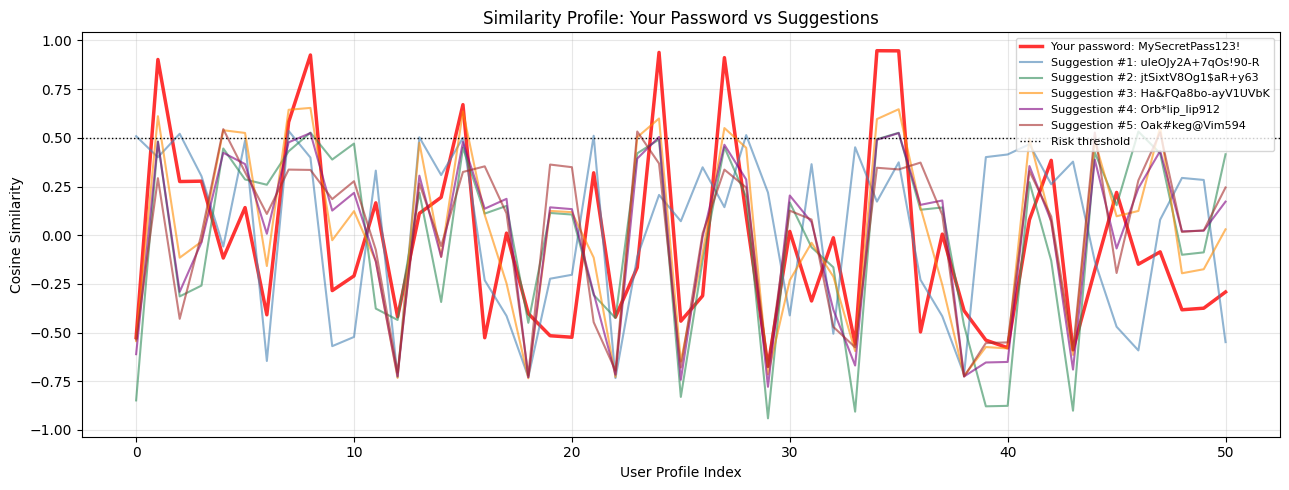

Good suggestions should have LOW and FLAT similarity lines across all users.


In [36]:
# Cell 11: Compare User Password vs Top Suggestions

compare_pws = [MY_PASSWORD] + top['password'].head(5).tolist()

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(profile_labels))
colors_cmp = ['red'] + ['steelblue','seagreen','darkorange','purple','brown']
labels_cmp = ['Your password'] + [f'Suggestion #{i+1}' for i in range(5)]

for i, pw in enumerate(compare_pws):
    emb  = password_embedding(pw)
    sims = profile_matrix @ emb
    ax.plot(x, sims, color=colors_cmp[i], alpha=0.8 if i==0 else 0.6,
            lw=2.5 if i==0 else 1.5, label=f'{labels_cmp[i]}: {pw[:18]}')

ax.axhline(0.5, color='black', lw=1, linestyle=':', label='Risk threshold')
ax.set(title='Similarity Profile: Your Password vs Suggestions',
       xlabel='User Profile Index', ylabel='Cosine Similarity')
ax.legend(loc='upper right', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/comparison.png', dpi=150)
plt.show()
print('Good suggestions should have LOW and FLAT similarity lines across all users.')


In [37]:
# Cell 12: Save Final Outputs
scored_df.head(50).to_csv('/kaggle/working/phase3_top50_passwords.csv', index=False)

with open('/kaggle/working/phase3_top_passwords.txt', 'w') as f:
    f.write('# Phase 3: Top Keystroke-Resistant Password Suggestions\n')
    f.write(f'# Scoring: {ADV_WEIGHT*100:.0f}% adversarial distance + {STR_WEIGHT*100:.0f}% strength\n')
    f.write(f'# Generated from {N_CANDIDATES} candidates\n\n')
    for i, row in scored_df.head(TOP_N).iterrows():
        f.write(f'{row["password"]}\n')
        

summary = {
    'n_candidates'          : N_CANDIDATES,
    'top_n'                 : TOP_N,
    'adv_weight'            : ADV_WEIGHT,
    'strength_weight'       : STR_WEIGHT,
    'top10_mean_adv_score'  : round(float(scored_df.head(10)['adv_score'].mean()), 4),
    'top10_mean_entropy'    : round(float(scored_df.head(10)['entropy_bits'].mean()), 1),
    'top10_mean_strength'   : round(float(scored_df.head(10)['strength'].mean()), 4),
    'all_mean_adv_score'    : round(float(scored_df['adv_score'].mean()), 4),
}

with open('/kaggle/working/phase3_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('Phase 3 outputs:')
for fn in ['phase3_analysis.png','phase3_top50_passwords.csv',
           'phase3_top_passwords.txt','phase3_summary.json',
           'password_eval.png','comparison.png']:
    path = f'/kaggle/working/{fn}'
    size = os.path.getsize(path) if os.path.exists(path) else 0
    print(f'  {fn:<40} ({size/1024:.1f} KB)')

print('\n-- Summary --')
for k, v in summary.items():
    print(f'  {k:<35}: {v}')


Phase 3 outputs:
  phase3_analysis.png                      (301.0 KB)
  phase3_top50_passwords.csv               (6.9 KB)
  phase3_top_passwords.txt                 (0.3 KB)
  phase3_summary.json                      (0.2 KB)
  password_eval.png                        (40.2 KB)
  comparison.png                           (389.4 KB)

-- Summary --
  n_candidates                       : 5000
  top_n                              : 10
  adv_weight                         : 0.6
  strength_weight                    : 0.4
  top10_mean_adv_score               : 0.3833
  top10_mean_entropy                 : 110.8
  top10_mean_strength                : 0.921
  all_mean_adv_score                 : 0.0532
